In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


data_path = r"C:\Users\main\Desktop\Projects\Retail Demand Forecasting"
output_path = data_path + r"\outputs"
eda_path = output_path + r"\eda"

os.makedirs(eda_path, exist_ok=True)

all_results = pd.read_csv(
    output_path + r"\model_evaluation_results.csv"
)

comparison_df = pd.read_csv(
    output_path + r"\actual_vs_predicted.csv"
)

comparison_df["Date"] = pd.to_datetime(comparison_df["Date"])

comparison_df = comparison_df.sort_values("Date").reset_index(drop=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Evaluation data loaded successfully!")

print("\nModel Results:")
display(all_results)

print("\nActual vs Predicted:")
display(comparison_df.head())

Evaluation data loaded successfully!

Model Results:


,Model,MAE,RMSE,WAPE (%)
0,Gradient Boosting,7.742010,9.288301,16.562720
1,Random Forest,9.826246,18.316767,21.021590
2,Linear Regression,75.986660,118.283267,162.560599
3,Naive Baseline (Yesterday's Sales),8.526316,10.172202,18.294749



Actual vs Predicted:


,Date,Actual Sales,Predicted Sales
0,2025-07-07,41.0,29.869337
1,2025-07-13,56.0,41.184893
2,2025-07-14,39.0,37.695242
3,2025-07-15,48.0,41.168958
4,2025-07-16,38.0,37.053482


In [2]:
actual = comparison_df["Actual Sales"]
predicted = comparison_df["Predicted Sales"]

mae = np.mean(np.abs(actual - predicted))

rmse = np.sqrt(
    np.mean((actual - predicted) ** 2)
)

total_actual = np.sum(np.abs(actual))

if total_actual != 0:
    wape = (
        np.sum(np.abs(actual - predicted))
        / total_actual
    ) * 100
else:
    wape = np.nan

bias = np.mean(predicted - actual)

print("Best Model Evaluation")
print("----------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")
print(f"Forecast Bias: {bias:.2f}")

Best Model Evaluation
----------------------
MAE:  7.74
RMSE: 9.29
WAPE: 16.56%
Forecast Bias: -3.52


In [3]:
best_model_row = all_results.loc[
    all_results["MAE"].idxmin()
]

best_model_name = best_model_row["Model"]
best_model_mae = best_model_row["MAE"]

baseline_row = all_results[
    all_results["Model"].str.contains(
        "Naive Baseline",
        case=False,
        na=False
    )
]

print("Best Performing Model:", best_model_name)
print("Best Model MAE:", round(best_model_mae, 2))

if not baseline_row.empty:
    baseline_mae = baseline_row.iloc[0]["MAE"]

    improvement = (
        (baseline_mae - best_model_mae) / baseline_mae
    ) * 100 if baseline_mae != 0 else np.nan

    print("Baseline MAE:", round(baseline_mae, 2))
    print("Improvement over baseline:", round(improvement, 2), "%")

Best Performing Model: Gradient Boosting
Best Model MAE: 7.74
Baseline MAE: 8.53
Improvement over baseline: 9.2 %


In [4]:
comparison_df["Prediction_Error"] = (
    comparison_df["Actual Sales"]
    - comparison_df["Predicted Sales"]
)

comparison_df["Absolute_Error"] = (
    comparison_df["Prediction_Error"].abs()
)

comparison_df.head(10)

,Date,Actual Sales,Predicted Sales,Prediction_Error,Absolute_Error
0,2025-07-07,41.0,29.869337,11.130663,11.130663
1,2025-07-13,56.0,41.184893,14.815107,14.815107
2,2025-07-14,39.0,37.695242,1.304758,1.304758
3,2025-07-15,48.0,41.168958,6.831042,6.831042
4,2025-07-16,38.0,37.053482,0.946518,0.946518
5,2025-07-18,28.0,36.960251,-8.960251,8.960251
6,2025-07-19,49.0,40.039450,8.960550,8.960550
7,2025-08-01,48.0,39.935819,8.064181,8.064181
8,2025-08-02,54.0,68.955093,-14.955093,14.955093
9,2025-08-03,57.0,40.867060,16.132940,16.132940


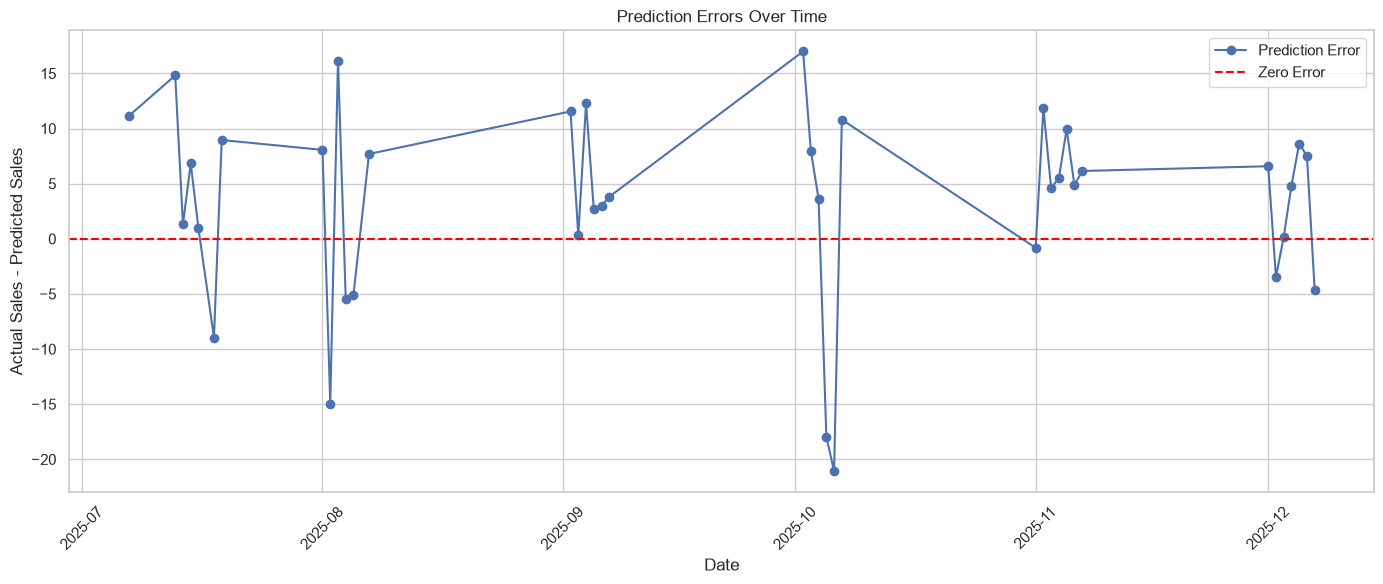

In [5]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparison_df["Date"],
    comparison_df["Prediction_Error"],
    marker="o",
    label="Prediction Error"
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red",
    label="Zero Error"
)

plt.title("Prediction Errors Over Time")
plt.xlabel("Date")
plt.ylabel("Actual Sales - Predicted Sales")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\13_prediction_errors_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

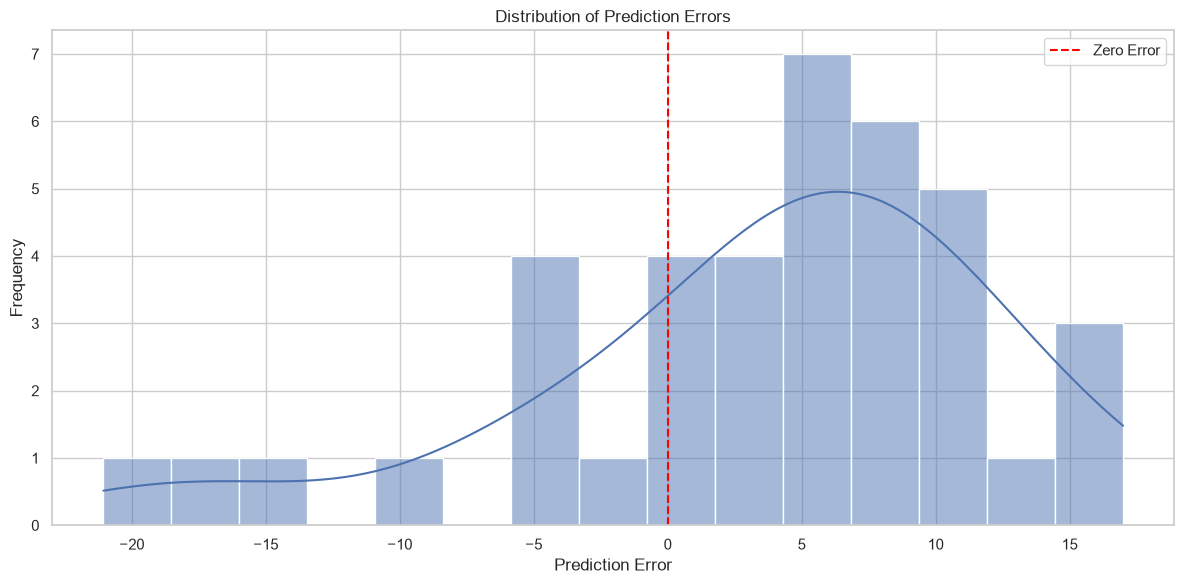

In [6]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=comparison_df,
    x="Prediction_Error",
    bins=15,
    kde=True
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\14_prediction_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

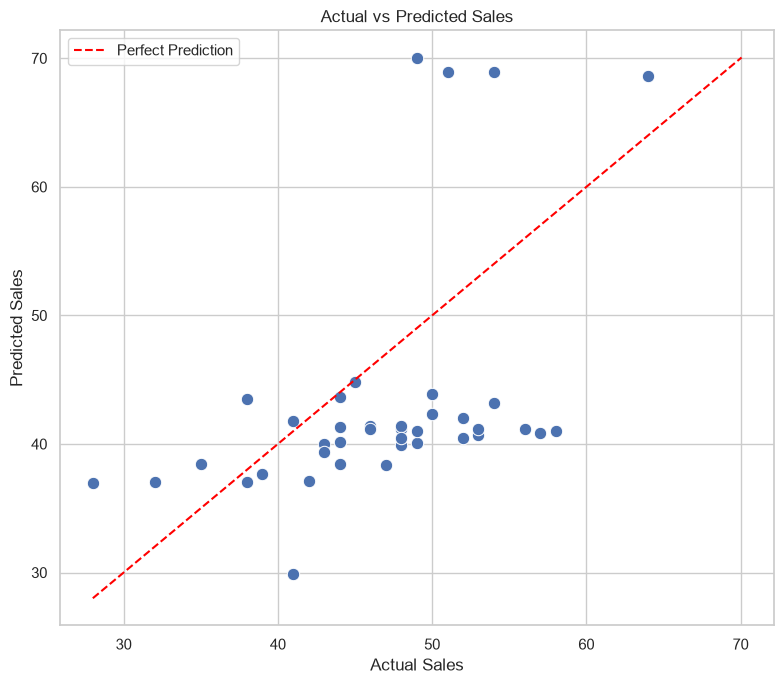

In [7]:
plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=comparison_df,
    x="Actual Sales",
    y="Predicted Sales",
    s=80
)

# Perfect prediction reference line
minimum = min(
    comparison_df["Actual Sales"].min(),
    comparison_df["Predicted Sales"].min()
)

maximum = max(
    comparison_df["Actual Sales"].max(),
    comparison_df["Predicted Sales"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.legend()
plt.tight_layout()

plt.savefig(
    eda_path + r"\15_actual_vs_predicted_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
largest_errors = comparison_df.sort_values(
    by="Absolute_Error",
    ascending=False
)

largest_errors[
    [
        "Date",
        "Actual Sales",
        "Predicted Sales",
        "Prediction_Error",
        "Absolute_Error"
    ]
].head(10)

,Date,Actual Sales,Predicted Sales,Prediction_Error,Absolute_Error
23,2025-10-06,49.0,70.061162,-21.061162,21.061162
22,2025-10-05,51.0,68.955093,-17.955093,17.955093
19,2025-10-02,58.0,41.007097,16.992903,16.992903
9,2025-08-03,57.0,40.867060,16.132940,16.132940
8,2025-08-02,54.0,68.955093,-14.955093,14.955093
1,2025-07-13,56.0,41.184893,14.815107,14.815107
15,2025-09-04,53.0,40.705199,12.294801,12.294801
26,2025-11-02,53.0,41.168958,11.831042,11.831042
13,2025-09-02,52.0,40.445558,11.554442,11.554442
0,2025-07-07,41.0,29.869337,11.130663,11.130663


In [11]:
# Load featured dataset to obtain weekday information
featured_df = pd.read_csv(
    output_path + r"\retail_demand_forecasting_featured.csv"
)

featured_df["Date"] = pd.to_datetime(featured_df["Date"])

# Attach weekday to prediction results
weekday_lookup = featured_df[
    ["Date", "Day_of_Week"]
].drop_duplicates(subset=["Date"])

comparison_df = comparison_df.merge(
    weekday_lookup,
    on="Date",
    how="left"
)

weekday_errors = (
    comparison_df.groupby("Day_of_Week")
    ["Absolute_Error"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .reset_index()
)

weekday_errors.columns = [
    "Day_of_Week",
    "Average_Absolute_Error"
]

display(weekday_errors)

,Day_of_Week,Average_Absolute_Error
0,Monday,8.358429
1,Tuesday,7.208433
2,Wednesday,2.846004
3,Thursday,9.333074
4,Friday,7.075669
5,Saturday,6.471346
6,Sunday,11.534289


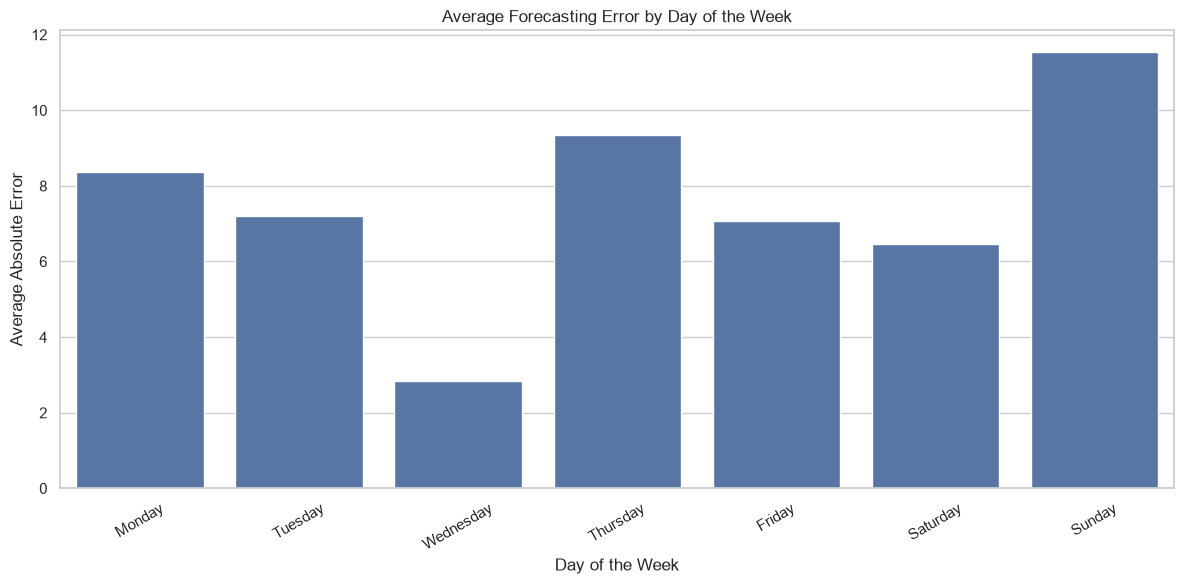

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=weekday_errors,
    x="Day_of_Week",
    y="Average_Absolute_Error"
)

plt.title("Average Forecasting Error by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Absolute Error")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    eda_path + r"\16_forecasting_error_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Create evaluation summary
evaluation_summary = pd.DataFrame([{
    "Best_Model": best_model_name,
    "MAE": mae,
    "RMSE": rmse,
    "WAPE_Percentage": wape,
    "Forecast_Bias": bias
}])

# Save evaluation summary
evaluation_summary.to_csv(
    output_path + r"\final_evaluation_summary.csv",
    index=False
)

# Save detailed prediction errors
comparison_df.to_csv(
    output_path + r"\detailed_prediction_errors.csv",
    index=False
)

# Save weekday error analysis
weekday_errors.to_csv(
    output_path + r"\weekday_error_analysis.csv",
    index=False
)

print("Evaluation reports saved successfully!")

Evaluation reports saved successfully!
